# TP2 – Genetic Algorithm (Python version)
**Goal:** maximise f(x) = -x² + 4x on the interval [1, 30].

**Fixed by the assignment**
- Population of 4 individuals (chromosomes), initial population: 18, 6, 11, 27
- Each individual is encoded on 5 bits (genes)
- Uniform crossover
- 4 scenarios to test:

| Scenario | Pc | Pm | max-generation |
|---|---|---|---|
| 1 | 0.75 | 0.005 | 30 |
| 2 | 0.75 | 0.005 | 50 |
| 3 | 0.90 | 0.01 | 30 |
| 4 | 0.90 | 0.01 | 50 |

**Statistics collected for each scenario:** execution time, fitness vector (one value per iteration), average fitness, maximum fitness, number of crossovers, number of mutations, number of accepted new solutions.

## 0. Imports

In [14]:
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Initialization and fitness function

**Objective function.** We maximise f(x) = -x² + 4x on the interval [1, 30].

**Chromosome representation.** Each solution x is encoded as a chromosome of 5 bits
(genes), because 2⁵ = 32 values can be represented (0 to 31) and the interval needs
values up to 30. Example: 18 → 10010, 6 → 00110, 11 → 01011, 27 → 11011.

**Initial population.** 4 individuals given by the assignment: 18, 6, 11, 27.

**Fitness evaluation.** The fitness of a chromosome is f(x), where x is its decoded
integer value. All four initial individuals have a negative fitness, because the
maximum of f is at x = 2 and they are far from it.

**Handling x = 0 and x = 31.** 5 bits can also represent 0 and 31, which are outside
[1, 30]. Crossover or mutation can produce them, so we use a penalty: any chromosome
outside [1, 30] gets a very bad fitness (-10⁹). It is therefore never selected and
never accepted into the population.

In [15]:
N_BITS = 5  # chromosome length
X_MIN, X_MAX = 1, 30  # valid interval for x
POP_SIZE = 4  # population size
INITIAL_POP = [18, 6, 11, 27]  # given initial population
PENALTY = -1e9  # fitness of invalid chromosomes (x = 0 or x = 31)


def encode(x):
    """integer -> list of 5 bits, e.g. 18 -> [1,0,0,1,0]"""
    return [int(b) for b in format(x, f"0{N_BITS}b")]


def decode(chrom):
    """list of 5 bits -> integer, e.g. [1,0,0,1,0] -> 18"""
    return int("".join(map(str, chrom)), 2)


def f(x):
    """objective function"""
    return -(x**2) + 4 * x


def fitness(chrom):
    """fitness of a chromosome, with a penalty outside [1, 30]"""
    x = decode(chrom)
    if x < X_MIN or x > X_MAX:
        return PENALTY
    return f(x)


def initial_population():
    return [encode(x) for x in INITIAL_POP]


# quick check
for x in INITIAL_POP:
    print(f"x = {x:2d}  chromosome = {encode(x)}  fitness = {fitness(encode(x))}")
print("x = 0 ->", fitness(encode(0)), "| x = 31 ->", fitness(encode(31)))


x = 18  chromosome = [1, 0, 0, 1, 0]  fitness = -252
x =  6  chromosome = [0, 0, 1, 1, 0]  fitness = -12
x = 11  chromosome = [0, 1, 0, 1, 1]  fitness = -77
x = 27  chromosome = [1, 1, 0, 1, 1]  fitness = -621
x = 0 -> -1000000000.0 | x = 31 -> -1000000000.0


## 2. Selection

**Method: tournament selection.** To pick one parent, we draw 2 individuals at random (with replacement). The one with the better fitness wins with probability p = 0.8, otherwise the weaker one wins. We repeat this POP_SIZE = 4 times to get 4 parents.

**Why tournament.** It only compares two fitness values, so it works with the negative fitness of f(x) = -x² + 4x. It also keeps some diversity, because a weaker individual can still win.

**Implementation notes.**
- `tournament(population)` returns one winner. `selection(population)` calls it 4 times.
- The winner is returned as a copy (`winner[:]`), so crossover and mutation never modify the old population.
- p is the same in all 4 scenarios.

In [16]:
TOURNAMENT_P = 0.8  # probability that the fitter of the 2 contestants wins


def tournament(population):
    """Draw 2 individuals (with replacement), the fitter one wins with probability p."""
    a = random.choice(population)
    b = random.choice(population)
    better, worse = (a, b) if fitness(a) >= fitness(b) else (b, a)
    winner = better if random.random() < TOURNAMENT_P else worse
    return winner[:]  # copy, so later crossover/mutation don't modify the population


def selection(population):
    """Return POP_SIZE parents chosen by tournament."""
    return [tournament(population) for _ in range(POP_SIZE)]


# quick check: how often is each individual selected over 10000 draws?
from collections import Counter

pop = initial_population()
counts = Counter()
for _ in range(10000):
    for parent in selection(pop):
        counts[decode(parent)] += 1
for x in INITIAL_POP:
    print(f"x = {x:2d}  fitness = {f(x):5d}  selected {counts[x]/40000:.1%} of the time")

x = 18  fitness =  -252  selected 21.1% of the time
x =  6  fitness =   -12  selected 36.5% of the time
x = 11  fitness =   -77  selected 28.7% of the time
x = 27  fitness =  -621  selected 13.7% of the time


## 3. Uniform Crossover

**Method: Uniform crossover.** For each gene position, a random mask (0 or 1) is generated. If the mask is 0, the child takes the gene from Parent 1. If the mask is 1, it takes the gene from Parent 2. With 5 bits, there are \(2^5 = 32\) possible masks.

**Role of \(P_c\).** \(P_c\) determines the crossover frequency. If `random.random() < pc` (0.75 or 0.90), the crossover is performed. Otherwise, children are exact copies of the parents.

**Implementation notes.** A global variable `nb_croisements` is incremented each time a crossover is actually performed.




In [17]:
nb_croisements = 0

def uniform_crossover(parent1, parent2, pc):
    global nb_croisements
    
    if random.random() < pc:
        nb_croisements += 1
        
        child1 = []
        child2 = []
        
        for i in range(N_BITS):
            if random.choice([0, 1]) == 0:
                child1.append(parent1[i])
                child2.append(parent2[i])
            else:
                child1.append(parent2[i])
                child2.append(parent1[i])
                
        return child1, child2
    else:
        return parent1[:], parent2[:]

### Test de validation (Scénario 1)
Test du croisement avec les paramètres du Scénario 1 (\(P_c = 0.75\)).

In [18]:
pop = initial_population()
parents = selection(pop)
parent1 = parents[0]
parent2 = parents[1]

pc = 0.75
child1, child2 = uniform_crossover(parent1, parent2, pc)

print(f"Parent 1 : {parent1} (x = {decode(parent1):2d})")
print(f"Parent 2 : {parent2} (x = {decode(parent2):2d})")
print(f"Enfant 1 : {child1} (x = {decode(child1):2d})")
print(f"Enfant 2 : {child2} (x = {decode(child2):2d})")
print(f"Nombre de croisements effectués : {nb_croisements}")

Parent 1 : [0, 1, 0, 1, 1] (x = 11)
Parent 2 : [0, 1, 0, 1, 1] (x = 11)
Enfant 1 : [0, 1, 0, 1, 1] (x = 11)
Enfant 2 : [0, 1, 0, 1, 1] (x = 11)
Nombre de croisements effectués : 0


## 4. Mutation

**Method: bit-flip mutation, one test per individual.** For each child, a random number is drawn. If `random.random() < pm`, the individual mutates: one gene is chosen at random and flipped (0 → 1 or 1 → 0). Otherwise the child is unchanged.

**Role of Pm.** Pm is the probability that a mutation happens at all. It is very small (0.005 or 0.01), so mutations are rare. They add diversity but cannot drive the search alone.

**Implementation notes.**
- The mutation works on a copy, so the original chromosome is never modified.
- A global counter `nb_mutations` is incremented each time a mutation is actually performed.
- A mutation can produce x = 0 or x = 31. These get the penalty fitness and are rejected at the acceptance step.

In [19]:
nb_mutations = 0

def mutate(chrom, pm):
    """Mutate one random bit with probability pm."""
    global nb_mutations

    # Work on a copy
    child = chrom[:]

    # Decide whether this chromosome will mutate
    if random.random() < pm:

        # Choose one random bit (0 to 4)
        i = random.randrange(N_BITS)

        # Flip the selected bit
        child[i] = 1 - child[i]

        # Count the actual mutation
        nb_mutations += 1

    return child

## 5. Elitist replacement

After crossover and mutation, we have 4 old individuals (parents) and 4 new ones (children). To build generation t+1, we put them all in one pool, sort it by fitness (best first) and keep the 4 best.

**Why this works.**
- The best solution found so far can never be lost (elitism).
- A child is only accepted if it is better than some parent, which matches the step "accepter les nouvelles solutions si leur fitness est amélioré".
- Invalid children (x = 0 or 31) have the penalty fitness, so they end last and are always rejected.

**Number of accepted solutions.** We count how many children end up in the new population. This is the statistic "nombre de nouvelles solutions acceptées".

**Limit.** Elitism can fill the population with copies of the same good individual, which reduces diversity.

In [20]:
def elitist_replacement(population, children):
    """Keep the POP_SIZE best among parents + NEW children (no duplicates)."""
    pool = [(fitness(c), False, c) for c in population]

    for c in children:
        if all(c != p for _, _, p in pool):      # skip clones of existing individuals
            pool.append((fitness(c), True, c))

    pool.sort(key=lambda e: (e[0], not e[1]), reverse=True)
    survivors = pool[:POP_SIZE]

    new_population = [c for _, _, c in survivors]
    nb_accepted = sum(1 for _, is_child, _ in survivors if is_child)
    return new_population, nb_accepted

### Test d'une itération (Scénario 1 : Pc = 0.75, Pm = 0.005)
Une seule itération : sélection des 4 parents, croisement des paires (0,1) et (2,3), puis mutation de chaque enfant.

In [21]:
pc, pm = 0.75, 0.01         # Scenario 1
nb_croisements = 0            # reset the counters
nb_mutations = 0

pop = initial_population()
parents = selection(pop)                                 # 4 parents

# crossover on the pairs (0,1) and (2,3) -> 4 children
c1, c2 = uniform_crossover(parents[0], parents[1], pc)
c3, c4 = uniform_crossover(parents[2], parents[3], pc)
children = [c1, c2, c3, c4]

# mutation applied to each child
mutated = [mutate(c, pm) for c in children]

for i in range(4):
    print(f"Parent {i+1} : x = {decode(parents[i]):2d} | "
          f"Enfant : x = {decode(children[i]):2d} | "
          f"Après mutation : x = {decode(mutated[i]):2d}")
print(f"Croisements : {nb_croisements} | Mutations : {nb_mutations}")
new_pop, nb_accepted = elitist_replacement(pop, mutated)

print("Ancienne population :", [(decode(c), fitness(c)) for c in pop])
print("Enfants             :", [(decode(c), fitness(c)) for c in mutated])
print("Nouvelle population :", [(decode(c), fitness(c)) for c in new_pop])
print(f"Enfants acceptés    : {nb_accepted}")

Parent 1 : x = 18 | Enfant : x =  6 | Après mutation : x =  6
Parent 2 : x =  6 | Enfant : x = 18 | Après mutation : x = 18
Parent 3 : x = 11 | Enfant : x = 11 | Après mutation : x = 11
Parent 4 : x = 11 | Enfant : x = 11 | Après mutation : x = 11
Croisements : 1 | Mutations : 0
Ancienne population : [(18, -252), (6, -12), (11, -77), (27, -621)]
Enfants             : [(6, -12), (18, -252), (11, -77), (11, -77)]
Nouvelle population : [(6, -12), (11, -77), (18, -252), (27, -621)]
Enfants acceptés    : 0


### Test de la mutation sur plusieurs générations

In [22]:
pm = 0.05                        # demo value only
N_GEN = 20                       # demo number of generations
chrom = encode(13)               # demo chromosome

expected = pm * POP_SIZE * N_GEN
print(f"Pm = {pm} | tests = {POP_SIZE * N_GEN} | attendu = {expected:.1f} mutations\n")

for run in range(1, 6):          # repeat the whole experiment 5 times
    nb_mutations = 0             # reset before each run
    for gen in range(N_GEN):
        for _ in range(POP_SIZE):        # 4 tests per generation
            mutate(chrom, pm)
    print(f"Expérience {run} : {nb_mutations} mutations")

Pm = 0.05 | tests = 80 | attendu = 4.0 mutations

Expérience 1 : 4 mutations
Expérience 2 : 2 mutations
Expérience 3 : 4 mutations
Expérience 4 : 5 mutations
Expérience 5 : 4 mutations


## 6. Full Genetic Algorithm

This function brings together all the previous steps (initialisation, selection, crossover, mutation, elitist replacement) in a single function, `full_genetic_algorithm`. To run a scenario, we only need to call it with the parameters of that scenario, and it returns all the statistics requested by the TP.

### Parameters

| Parameter | Role |
|---|---|
| `pc` | crossover probability |
| `pm` | mutation probability |
| `max_generation` | number of generations to run |

### Workflow

We start from the initial population [18, 6, 11, 27], then, at each generation:

1. **Selection**: 4 parents are chosen by tournament.
2. **Crossover**: the parents are crossed in pairs (0, 1) and (2, 3) with probability `pc`, which gives 4 children. The counter `nb_crossovers` is incremented each time a crossover actually takes place.
3. **Mutation**: each child mutates with probability `pm`. The counter `nb_mutations` is incremented each time a mutation actually takes place.
4. **Elitist replacement**: parents and children compete, and the 4 best individuals form the new population. We also get the number of children accepted.
5. **Statistics**: we record the best fitness, the mean fitness of the population and the number of accepted children for this generation.

### Returned results

The function returns a dictionary:

| Key | Content | TP statistic |
|---|---|---|
| `execution_time` | execution time in seconds | execution time |
| `fitness_vector` | best fitness at each generation | fitness vector |
| `mean_fitness_per_gen` | mean fitness of the population at each generation | (diversity analysis) |
| `mean_fitness` | average of `mean_fitness_per_gen` over all generations | mean fitness |
| `max_fitness` | largest value of `fitness_vector` | maximum fitness |
| `nb_crossovers` | total number of crossovers performed | number of crossovers |
| `nb_mutations` | total number of mutations performed | number of mutations |
| `nb_accepted` | total number of children accepted into the population | number of new accepted solutions |
| `accepted_per_gen` | children accepted at each generation | (accepted solutions chart) |
| `best_x` | best individual of the final population | final result |
| `final_population` | decoded final population | final result |

### Remarks

- Results differ from one run to another, because selection, crossover and mutation rely on random draws.
- Thanks to elitist replacement, the best solution is never lost: `fitness_vector` can therefore never decrease.

In [23]:
def full_genetic_algorithm(pc, pm, max_generation):
    """Run the genetic algorithm and return all the requested statistics.

    pc             : crossover probability
    pm             : mutation probability
    max_generation : number of generations
    """
    global nb_croisements, nb_mutations

    start = time.perf_counter()

    # Initialisation
    population = initial_population()
    nb_croisements = 0   # reset the global counters at each run
    nb_mutations = 0
    nb_accepted_total = 0

    best_history = []      # best fitness at each generation
    mean_history = []      # mean fitness of the population at each generation
    accepted_history = []  # number of new solutions accepted at each generation

    for _ in range(max_generation):
        # 1. Selection: choose POP_SIZE parents by tournament
        parents = selection(population)

        # 2. Crossover on pairs (0,1) and (2,3)
        children = []
        for i in range(0, POP_SIZE, 2):
            c1, c2 = uniform_crossover(parents[i], parents[i + 1], pc)
            children += [c1, c2]

        # 3. Mutation applied to each child
        mutated = [mutate(c, pm) for c in children]

        # 4. Elitist replacement: keep the best among parents and children
        population, nb_accepted = elitist_replacement(population, mutated)
        nb_accepted_total += nb_accepted

        # 5. Statistics of this generation
        fits = [fitness(c) for c in population]
        best_history.append(max(fits))
        mean_history.append(sum(fits) / len(fits))
        accepted_history.append(nb_accepted)

    elapsed = time.perf_counter() - start
    best = max(population, key=fitness)

    return {
        "execution_time": elapsed,
        "fitness_vector": best_history,
        "mean_fitness_per_gen": mean_history,
        "mean_fitness": sum(mean_history) / len(mean_history),
        "max_fitness": max(best_history),
        "nb_crossovers": nb_croisements,
        "nb_mutations": nb_mutations,
        "nb_accepted": nb_accepted_total,
        "accepted_per_gen": accepted_history,
        "best_x": decode(best),
        "final_population": [decode(c) for c in population],
    }

## 7. Simulation & Results

In this section, we run the complete genetic algorithm (`full_genetic_algorithm`) on the four scenarios of the TP. All scenarios use the same code, the same initial population [18, 6, 11, 27], tournament selection (p = 0.8), uniform crossover and elitist replacement. Only the values of `pc`, `pm` and `max_generation` change.

| Scenario | Pc | Pm | max_generation |
|---|---|---|---|
| 1 | 0.75 | 0.005 | 30 |
| 2 | 0.75 | 0.005 | 50 |
| 3 | 0.90 | 0.01 | 30 |
| 4 | 0.90 | 0.01 | 50 |

The statistics of each scenario are stored in the dictionary `results`, so that they can be reused later to plot the comparison graphs. Since the algorithm relies on random draws, the exact values change from one run to another.

In [24]:
results = {}  # stores the statistics of each scenario

def print_results(name, r):
    """Display the statistics requested by the TP for one scenario."""
    print(f"===== {name} =====")
    print(f"Execution time   : {r['execution_time'] * 1000:.3f} ms")
    print(f"Fitness vector   : {r['fitness_vector']}")
    print(f"Mean fitness     : {r['mean_fitness']:.2f}")
    print(f"Max fitness      : {r['max_fitness']}")
    print(f"Crossovers       : {r['nb_crossovers']}")
    print(f"Mutations        : {r['nb_mutations']}")
    print(f"Accepted children: {r['nb_accepted']}")
    print(f"Best x           : {r['best_x']}")
    print(f"Final population : {r['final_population']}")

### 7.1 **Scenario 1:** Pc = 0.75, Pm = 0.005, max_generation = 30

In [25]:
results["Scenario 1"] = full_genetic_algorithm(pc=0.75, pm=0.005, max_generation=30)
print_results("Scenario 1", results["Scenario 1"])

===== Scenario 1 =====
Execution time   : 1.287 ms
Fitness vector   : [-12, 3, 3, 3, 3, 3, 3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
Mean fitness     : -24.83
Max fitness      : 4
Crossovers       : 36
Mutations        : 1
Accepted children: 5
Best x           : 2
Final population : [2, 3, 6, 7]


### 7.2 **Scenario 2:** Pc = 0.75, Pm = 0.005, max_generation = 50

Same probabilities as Scenario 1, but with more generations. This lets us measure the effect of `max_generation` alone.

In [26]:
results["Scenario 2"] = full_genetic_algorithm(pc=0.75, pm=0.005, max_generation=50)
print_results("Scenario 2", results["Scenario 2"])

===== Scenario 2 =====
Execution time   : 2.781 ms
Fitness vector   : [3, 3, 3, 3, 3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
Mean fitness     : -13.38
Max fitness      : 4
Crossovers       : 72
Mutations        : 1
Accepted children: 4
Best x           : 2
Final population : [2, 3, 6, 7]


### 7.3 **Scenario 3:** Pc = 0.90, Pm = 0.01, max_generation = 30

Higher crossover and mutation probabilities than Scenario 1, with the same number of generations. This lets us measure the effect of `pc` and `pm` alone.

In [27]:
results["Scenario 3"] = full_genetic_algorithm(pc=0.90, pm=0.01, max_generation=30)
print_results("Scenario 3", results["Scenario 3"])

===== Scenario 3 =====
Execution time   : 1.360 ms
Fitness vector   : [-12, 3, 3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
Mean fitness     : -11.32
Max fitness      : 4
Crossovers       : 52
Mutations        : 0
Accepted children: 3
Best x           : 2
Final population : [2, 3, 6, 7]


### 7.4 **Scenario 4:** Pc = 0.90, Pm = 0.01, max_generation = 50

Highest probabilities and highest number of generations: this scenario combines the changes of Scenarios 2 and 3.

In [28]:
results["Scenario 4"] = full_genetic_algorithm(pc=0.90, pm=0.01, max_generation=50)
print_results("Scenario 4", results["Scenario 4"])

===== Scenario 4 =====
Execution time   : 1.913 ms
Fitness vector   : [4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
Mean fitness     : -18.36
Max fitness      : 4
Crossovers       : 92
Mutations        : 3
Accepted children: 4
Best x           : 2
Final population : [2, 3, 6, 7]


## 8.  Comparison graphs

In this section, we compare the four scenarios graphically, using the statistics stored in the dictionary `results`. Each graph is saved as a `.png` file so that it can be inserted in the report.

The helper function `bar_chart` draws a bar chart for one statistic and is reused for graphs b to g. The same colour is used for each scenario in all the graphs, which makes the comparison easier.

In [31]:
import matplotlib.pyplot as plt

names = list(results.keys())  # ["Scenario 1", ..., "Scenario 4"]
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]


def bar_chart(key, title, ylabel, filename, scale=1, fmt="{:.2f}"):
    """Bar chart comparing one statistic across the 4 scenarios."""
    values = [results[n][key] * scale for n in names]

    fig, ax = plt.subplots(figsize=(7, 4))
    bars = ax.bar(names, values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values])
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.3)

    plt.savefig(filename, dpi=200, bbox_inches="tight")
    plt.show()

### 8.1 Fitness vector

This graph shows the best fitness of the population at each generation, for the four scenarios. It lets us compare how fast each scenario reaches the optimum (f(2) = 4) and how stable the fitness is afterwards. Scenarios 1 and 3 have 30 points, scenarios 2 and 4 have 50.

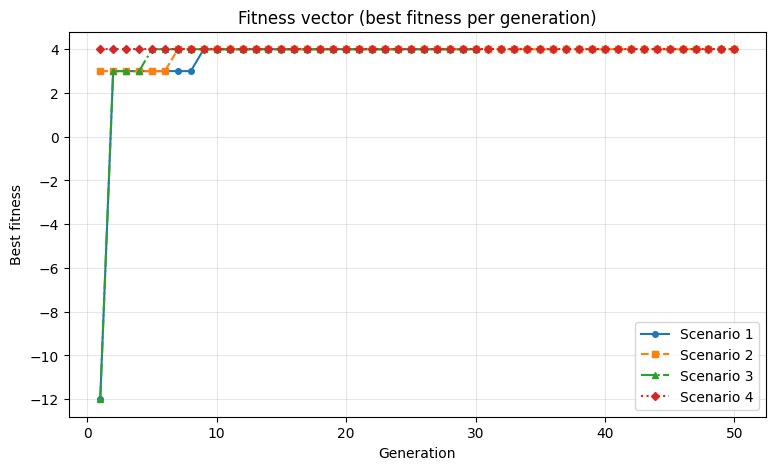

In [32]:
fig, ax = plt.subplots(figsize=(9, 5))

markers = ["o", "s", "^", "D"]
styles = ["-", "--", "-.", ":"]

for n, c, m, s in zip(names, colors, markers, styles):
    vector = results[n]["fitness_vector"]
    generations = range(1, len(vector) + 1)
    ax.plot(generations, vector, color=c, marker=m, linestyle=s,
            markersize=4, label=n)

ax.set_title("Fitness vector (best fitness per generation)")
ax.set_xlabel("Generation")
ax.set_ylabel("Best fitness")
ax.grid(alpha=0.3)
ax.legend()

plt.savefig("graph_a_fitness_vector.png", dpi=200, bbox_inches="tight")
plt.show()

### 8.2 Mean fitness

This graph compares the mean fitness of each scenario, computed as the average over all generations of the mean fitness of the population. It reflects the overall quality of the population during the whole run, not only the best individual.

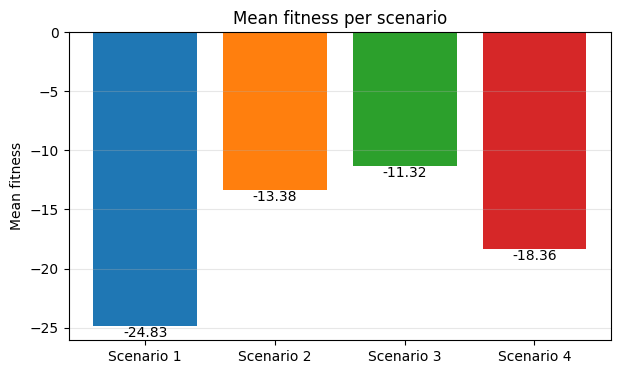

In [33]:
bar_chart("mean_fitness", "Mean fitness per scenario", "Mean fitness",
          "graph_b_mean_fitness.png")

### 8.3 Maximum fitness

This graph compares the best fitness reached during the whole execution. The optimum of f(x) = -x² + 4x on [1, 30] is f(2) = 4, so this value is the reference for the comparison.

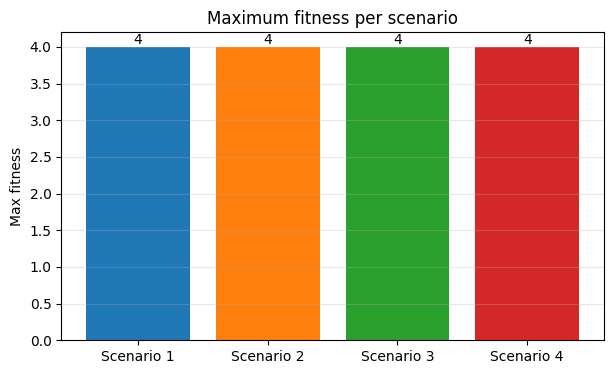

In [34]:
bar_chart("max_fitness", "Maximum fitness per scenario", "Max fitness",
          "graph_c_max_fitness.png", fmt="{:.0f}")

### 8.4 Execution time

This graph compares the execution time of the algorithm, in milliseconds, for each scenario. The time depends mainly on the number of generations, but it can also vary slightly from one run to another because of the machine load.

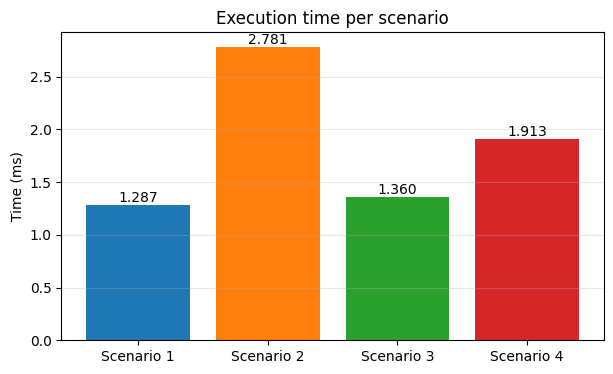

In [35]:
bar_chart("execution_time", "Execution time per scenario", "Time (ms)",
          "graph_d_execution_time.png", scale=1000, fmt="{:.3f}")

### 8.5 Number of crossovers

This graph shows the number of crossovers actually performed in each scenario. At each generation, the 4 parents form 2 pairs, so the maximum possible number of crossovers is 2 × max-generation (60 for 30 generations, 100 for 50 generations).

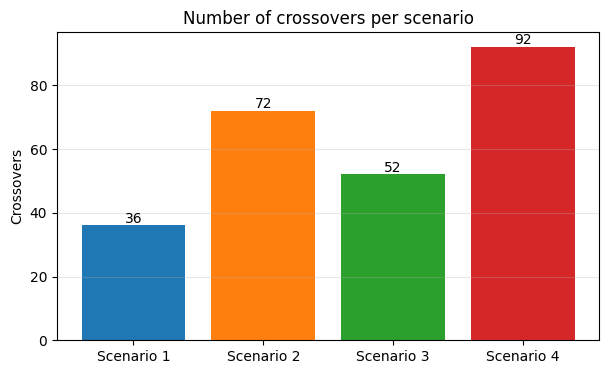

In [36]:
bar_chart("nb_crossovers", "Number of crossovers per scenario", "Crossovers",
          "graph_e_crossovers.png", fmt="{:.0f}")

### 8.6 Number of mutations

This graph shows the number of mutations actually performed in each scenario. At each generation, the 4 children are tested for mutation, so the number of tests is 4 × max-generation (120 for 30 generations, 200 for 50 generations).

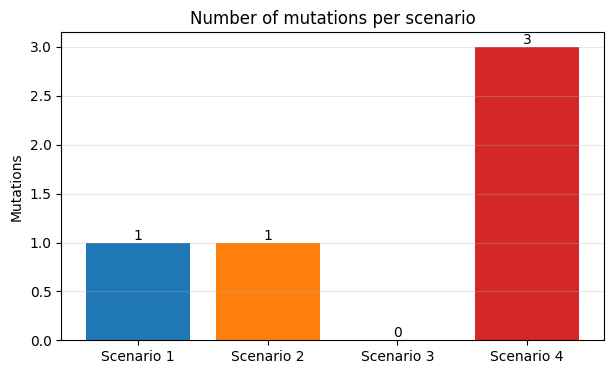

In [37]:
bar_chart("nb_mutations", "Number of mutations per scenario", "Mutations",
          "graph_f_mutations.png", fmt="{:.0f}")

### 8.7 Number of accepted new solutions

This graph shows the total number of children accepted into the population by the elitist replacement. A child is accepted only if it is different from all the individuals already present and if its fitness is among the 4 best.

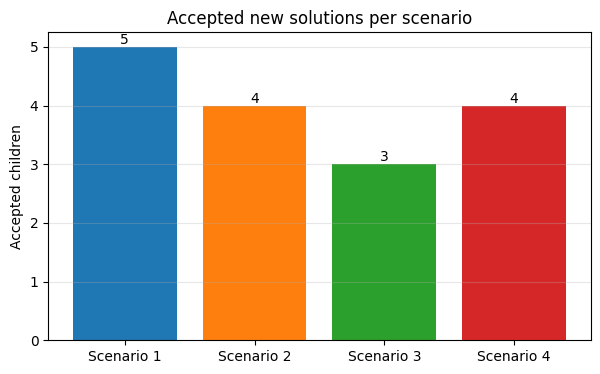

In [38]:
bar_chart("nb_accepted", "Accepted new solutions per scenario", "Accepted children",
          "graph_g_accepted.png", fmt="{:.0f}")